# 2. Multi-AMR Path Planning and Subcarrier Allocation

## 0. Import & `project_config.py` 불러오기

In [ ]:
# =========================================================
# Import
# =========================================================
import heapq
import importlib
import itertools

from math import hypot, sqrt

import matplotlib.pyplot as plt
import numpy as np

from matplotlib.patches import Circle, Rectangle


# =========================================================
# project_config.py 불러오기
# =========================================================
import project_config
importlib.reload(project_config)

from project_config import (
    ROOM_X, ROOM_Y, BS_CENTER, RX_HEIGHT,
    N_SC, DF_HZ, P_REF_DBM, NOISE_SC_DBM,
    GRID_RES, N_ROWS, N_COLS, CELL_X, CELL_Y,
    OBSTACLES, R_QOS_REQUIRED_BPS,
    FINGERPRINT_PATH, PATH_PLANNING_RESULTS_PATH,
    DATA_DIR, FIGURES_DIR,
    AMR1_START_XY, AMR1_GOAL_XY, AMR2_START_XY, AMR2_GOAL_XY,
    AMR1_SPEED_MPS as AMR1_SPEED, AMR2_SPEED_MPS as AMR2_SPEED,
    AMR1_START_TIME_S as AMR1_START_TIME,
    AMR2_START_TIME_S as AMR2_START_TIME,
    OBSTACLE_BUFFER_M as OBSTACLE_BUFFER,
    SIM_DT_S as SIM_DT,
    N_PATH_CANDIDATES as K_CANDIDATES,
    MAX_PATH_RATIO, MAX_CANDIDATE_ATTEMPT_FACTOR,
    RANDOM_SEED, AMR1_LINK_OFFSET_DB, AMR2_LINK_OFFSET_DB,
)

DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Planning grid:", (N_ROWS, N_COLS))
print("Grid resolution:", GRID_RES, "m")
print("Obstacle 개수:", len(OBSTACLES))

## 0. Step 1에서 생성한 `fingerprint.npz` 불러오기

In [ ]:
if not FINGERPRINT_PATH.exists():
    raise FileNotFoundError(f"파일을 찾을 수 없습니다: {FINGERPRINT_PATH}")

with np.load(FINGERPRINT_PATH, allow_pickle=False) as data:
    H = data["H"]
    snr_db = data["snr_db"]
    snr_sc_linear_map = data["snr_sc_linear"]

    CELL_X = data["cell_x"]
    CELL_Y = data["cell_y"]
    SC_RF_HZ = data["sc_rf_hz"]

    GRID_RES = float(data["grid_res"].item())
    ROOM_X = float(data["room_x"].item())
    ROOM_Y = float(data["room_y"].item())

# shape도 Task 1 결과에서 결정
N_ROWS, N_COLS, N_SC = H.shape

print(f"Fingerprint loaded: H={H.shape}")

## 1. `project_config.py`의 planning parameter 불러오기

In [ ]:
# Occupancy grid
MAX_CANDIDATE_ATTEMPTS = MAX_CANDIDATE_ATTEMPT_FACTOR * K_CANDIDATES

# 입력값 검증
if AMR1_SPEED <= 0 or AMR2_SPEED <= 0:
    raise ValueError("AMR 속도는 0보다 커야 합니다.")
if SIM_DT <= 0:
    raise ValueError("SIM_DT는 0보다 커야 합니다.")
if K_CANDIDATES < 1 or MAX_PATH_RATIO < 1.0:
    raise ValueError("후보 경로 설정값을 확인하세요.")

## 2. occupancy grid 생성 (각 셀에 obstacle이 있는지 없는지)

In [ ]:
def build_occupancy_grid(obstacle_buffer=OBSTACLE_BUFFER):
    """True: 이동 불가능, False: 이동 가능"""

    # 격자 중심 좌표 만들기
    grid_x, grid_y = np.meshgrid(CELL_X, CELL_Y)
    blocked = np.zeros((N_ROWS, N_COLS), dtype=bool)   # 모든 cell을 false로 설정

    for obstacle in OBSTACLES:
        center_x, center_y = obstacle["center"]
        kind = obstacle["kind"]

        # cylinder obstacle이 cell 안에 있으면 true
        if kind == "cylinder":
            distance = np.hypot(grid_x - center_x, grid_y - center_y)
            blocked |= distance <= obstacle["radius"] + obstacle_buffer

        # box obstacle이 cell 안에 있으면 true로
        elif kind == "box":
            size_x, size_y, _ = obstacle["size"]
            outside_x = np.maximum(np.abs(grid_x - center_x) - size_x/2, 0)
            outside_y = np.maximum(np.abs(grid_y - center_y) - size_y/2, 0)
            blocked |= np.hypot(outside_x, outside_y) <= obstacle_buffer

        else:
            raise ValueError(f"지원하지 않는 장애물 종류: {kind}")

    return blocked


blocked = build_occupancy_grid()
free_cells = np.argwhere(~blocked)

## 3. 좌표 <-> 격자 변환 함수

In [ ]:
# =========================================================
# 공간 좌표 (x, y)를 가까운 cell의 (row, col)로 변환
# =========================================================
def world_to_cell(x, y):
    x, y = float(x), float(y)

    if not (0 <= x <= ROOM_X and 0 <= y <= ROOM_Y):
        raise ValueError(f"좌표가 방 밖에 있습니다: ({x}, {y})")

    col = int(np.argmin(np.abs(CELL_X - x)))
    row = int(np.argmin(np.abs(CELL_Y - y)))
    return row, col


# =========================================================
# (row, col)을 해당 셀 중심의 실제 좌표 (x, y)로 변환
# =========================================================
def cell_to_world(cell):
    row, col = map(int, cell)

    if not (0 <= row < N_ROWS and 0 <= col < N_COLS):
        raise ValueError(f"cell이 grid 밖에 있습니다: {cell}")

    return float(CELL_X[col]), float(CELL_Y[row])


# =========================================================
# cell로 구성된 path를 실제 (x, y) 좌표로 변환
# =========================================================
def cells_to_xy(path):
    if path is None:
        return None
    return np.asarray([cell_to_world(cell) for cell in path], dtype=float)


# =========================================================
# AMR start와 goal의 좌표를 grid cell로 변환해두기
# =========================================================
AMR1_START_CELL = world_to_cell(*AMR1_START_XY)
AMR1_GOAL_CELL  = world_to_cell(*AMR1_GOAL_XY)
AMR2_START_CELL = world_to_cell(*AMR2_START_XY)
AMR2_GOAL_CELL  = world_to_cell(*AMR2_GOAL_XY)

AMR_ENDPOINTS = {
    "AMR1 start": AMR1_START_CELL,
    "AMR1 goal": AMR1_GOAL_CELL,
    "AMR2 start": AMR2_START_CELL,
    "AMR2 goal": AMR2_GOAL_CELL,
}

# 결과 출력
for name, cell in AMR_ENDPOINTS.items():
    print(f"{name:10s}: cell={cell}, center={cell_to_world(cell)}")

## 4. A*

A*: start에서 goal까지 obstacle을 피하며 가장 짧은 경로를 찾는 알고리즘\
\
f(n) = g(n) + h(n)\
\
n: 현재 있는 cell\
f: 예상되는 전체 path 거리\
g: 지금까지 실제로 이동한 거리\
h: goal까지 남은 예상 거리

In [ ]:
# 이동 가능한 8가지 방향: 앞뒤, 양옆, 대각선
MOVES_8 = [
    (-1, 0, 1.0), (1, 0, 1.0), (0, -1, 1.0), (0, 1, 1.0),
    (-1, -1, sqrt(2)), (-1, 1, sqrt(2)),
    (1, -1, sqrt(2)), (1, 1, sqrt(2)),
]


# =========================================================
# 현재 cell에서 goal까지의 Euclidean 거리
# =========================================================
def heuristic(cell, goal):
    r, c = cell
    rg, cg = goal
    return hypot(r - rg, c - cg)


# =========================================================
# 전체 path의 실제 길이를 m 단위로 계산
# =========================================================
def path_length_m(path):
    if path is None:
        return np.inf

    return GRID_RES * sum(
        hypot(r2 - r1, c2 - c1)
        for (r1, c1), (r2, c2) in zip(path[:-1], path[1:])
    )


# =========================================================
# A* 함수
# =========================================================
def astar(blocked, start, goal):
    """
    path     : start부터 goal까지의 (row, col) 목록
    length_m : 경로 길이 [m]
    """
    start, goal = tuple(start), tuple(goal)
    n_rows, n_cols = blocked.shape

    if blocked[start]:
        raise ValueError(f"start가 blocked cell입니다: {start}")
    if blocked[goal]:
        raise ValueError(f"goal이 blocked cell입니다: {goal}")

    counter = itertools.count()
    pq = [(heuristic(start, goal), next(counter), start)]
    g_score = {start: 0.0}
    came_from = {start: None}
    closed = set()

    while pq:
        _, _, current = heapq.heappop(pq)

        if current in closed:
            continue

        if current == goal:
            path = []
            while current is not None:
                path.append(current)
                current = came_from[current]

            path.reverse()
            return path, g_score[goal] * GRID_RES

        closed.add(current)
        r, c = current

        for dr, dc, move_cost in MOVES_8:
            nr, nc = r + dr, c + dc

            if not (0 <= nr < n_rows and 0 <= nc < n_cols):
                continue
            if blocked[nr, nc]:
                continue

            # 대각선 이동 시 장애물 모서리를 통과하지 못하도록 제한
            if dr != 0 and dc != 0:
                if blocked[r, nc] or blocked[nr, c]:
                    continue

            neighbor = (nr, nc)
            new_g = g_score[current] + move_cost

            if new_g >= g_score.get(neighbor, np.inf):
                continue

            g_score[neighbor] = new_g
            came_from[neighbor] = current
            priority = new_g + heuristic(neighbor, goal)
            heapq.heappush(pq, (priority, next(counter), neighbor))

    return None, np.inf

print("A* 함수 정의 완료")

## 5. AMR1, AMR2 최단경로 계산

In [ ]:
# AMR1에서 최단 경로 계산
AMR1_SHORTEST_PATH, AMR1_SHORTEST_LENGTH_M = astar(
    blocked, AMR1_START_CELL, AMR1_GOAL_CELL
)

# AMR2에서 최단 경로 계산
AMR2_SHORTEST_PATH, AMR2_SHORTEST_LENGTH_M = astar(
    blocked, AMR2_START_CELL, AMR2_GOAL_CELL
)

# path 찾았는지 확인: 없으면 print 됨
if AMR1_SHORTEST_PATH is None or AMR2_SHORTEST_PATH is None:
    raise RuntimeError("AMR 최단경로를 찾지 못했습니다.")

# cell로 된 path를 실제 (x, y) 좌표로 변환
AMR1_SHORTEST_XY = cells_to_xy(AMR1_SHORTEST_PATH)
AMR2_SHORTEST_XY = cells_to_xy(AMR2_SHORTEST_PATH)


# 경로 검증: obstacle을 통과하지는 않는지, path 길이가 맞게 계산되었는지
for name, path, length_m in [
    ("AMR1", AMR1_SHORTEST_PATH, AMR1_SHORTEST_LENGTH_M),
    ("AMR2", AMR2_SHORTEST_PATH, AMR2_SHORTEST_LENGTH_M),
]:
    if any(blocked[cell] for cell in path):
        raise ValueError(f"{name} 경로가 blocked cell을 통과합니다.")

    if not np.isclose(path_length_m(path), length_m):
        raise ValueError(f"{name} 경로 길이 계산이 일치하지 않습니다.")


# 각각의 AMR의 최단 경로 출력해보기
for name, path, length_m in [
    ("AMR1", AMR1_SHORTEST_PATH, AMR1_SHORTEST_LENGTH_M),
    ("AMR2", AMR2_SHORTEST_PATH, AMR2_SHORTEST_LENGTH_M),
]:
    print(f"{name}: {len(path)} cells, {length_m:.2f} m")

In [ ]:
# AMR1, AMR2 최단경로 시각화
import matplotlib.patheffects as pe

STROKE = [pe.withStroke(linewidth=4, foreground="black")]
fig, ax = plt.subplots(figsize=(11, 5.5))

# 평균 SNR 지도
im = ax.imshow(
    snr_db, origin="lower",
    extent=[0, ROOM_X, 0, ROOM_Y],
    cmap="turbo", aspect="equal",
)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Average SNR [dB]", fontsize=13)  # 제목 크기
cbar.ax.tick_params(labelsize=11)               # 눈금 숫자 크기

# 장애물과 안전거리 영역
blocked_mask = np.ma.masked_where(~blocked, blocked.astype(float))
ax.imshow(
    blocked_mask, origin="lower",
    extent=[0, ROOM_X, 0, ROOM_Y],
    cmap="Greys", vmin=0, vmax=1,
    alpha=0.75, aspect="equal",
)

# A* 최단경로
ax.plot(
    AMR1_SHORTEST_XY[:, 0], AMR1_SHORTEST_XY[:, 1],
    color="cyan", linestyle="-", linewidth=2.5,
    path_effects=STROKE,
    label=f"AMR1 shortest path ({AMR1_SHORTEST_LENGTH_M:.2f} m)",
    zorder=5,
)
ax.plot(
    AMR2_SHORTEST_XY[:, 0], AMR2_SHORTEST_XY[:, 1],
    color="orange", linestyle="--", linewidth=2.5,
    path_effects=STROKE,
    label=f"AMR2 shortest path ({AMR2_SHORTEST_LENGTH_M:.2f} m)",
    zorder=5,
)

# 시작점과 도착점
start_points = np.array([AMR1_SHORTEST_XY[0], AMR2_SHORTEST_XY[0]])
goal_points = np.array([AMR1_SHORTEST_XY[-1], AMR2_SHORTEST_XY[-1]])
ax.scatter(
    start_points[:, 0], start_points[:, 1],
    s=150, c="white", edgecolors="black",
    linewidths=1.5, marker="s", label="Start", zorder=6,
)
ax.scatter(
    goal_points[:, 0], goal_points[:, 1],
    s=170, c="white", edgecolors="black",
    linewidths=1.5, marker="^", label="Goal", zorder=6,
)
ax.scatter(
    *BS_CENTER[:2], s=340, c="white",
    edgecolors="black", linewidths=1.5,
    marker="*", label="BS", zorder=7,
)

# 그림 설정 및 저장
ax.set(
    xlim=(0, ROOM_X), ylim=(0, ROOM_Y),
    xlabel="x [m]", ylabel="y [m]",
)
# x축·y축 제목 크기
ax.set_xlabel("x [m]", fontsize=13)
ax.set_ylabel("y [m]", fontsize=13)
ax.set_title("Shortest Paths", fontsize=15)
ax.grid(alpha=0.2)
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "02_shortest_paths.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. candidate path 만들기

In [ ]:
# =========================================================
# candidate path의 signature를 생성하는 함수
# =========================================================
def path_signature(path):

    # A*가 경로를 찾지 못하거나 path에서 저장된 cell이 없는 경우
    if path is None or len(path) == 0:
        raise ValueError("빈 경로의 signature는 만들 수 없습니다.")

    # path에서 3칸마다 가져옴
    # ex) path = [A, B, C, D, E, F, G, H] 일 때, path[::3] = [A, D, G]
    sampled = tuple(tuple(cell) for cell in path[::3])

    # 목적지
    goal = tuple(path[-1])

    return sampled + (goal,)


# 5번 최단경로의 signature 확인
sig1 = path_signature(AMR1_SHORTEST_PATH)
sig2 = path_signature(AMR2_SHORTEST_PATH)

print("AMR1 signature:", sig1)
print("AMR2 signature:", sig2)

In [ ]:
# =========================================================
# candidate path를 생성하는 함수
# 출발점 ──A*──> 임의의 via cell ──A*──> 목적지
# =========================================================
def generate_candidate_paths(
    blocked, start, goal, shortest_path, shortest_length_m,
    k=K_CANDIDATES, max_ratio=MAX_PATH_RATIO,
    max_attempts=MAX_CANDIDATE_ATTEMPTS,
):
    
    # candidate path에 최단경로를 첫 번째로 포함시킴
    candidates = [shortest_path]
    lengths_m = [shortest_length_m]

    # 30개 중 최단경로 1개를 제외하고 29개만 만들면 됨
    seen = {path_signature(shortest_path)}

    stats = {
        "attempts": 0,           # via를 뽑은 전체 횟수
        "no_path": 0,            # via를 거쳐 goal까지 갈 수 없었던 횟수
        "too_long": 0,           # 길이 제한을 초과한 횟수
        "duplicate": 0,          # 기존 후보와 비슷해서 제외한 횟수
        "accepted_random": 0,    # 최종 candidate로 채택된 random path 수
    }

    # candidate path 최대 길이 계산
    length_limit_m = max_ratio * shortest_length_m

    # 최대 900번 via를 선택 (candidate path가 30개 만들어지면 반복문 break)
    for _ in range(max_attempts):
        if len(candidates) >= k:
            break

        # via를 한 번 선택할 때마다 시도 횟수 +1
        stats["attempts"] += 1

        # 이동 가능한 cell 중 임의의 via cell 선택
        via_idx = np.random.randint(len(free_cells))
        via = tuple(free_cells[via_idx])

        # start → via
        path_a, _ = astar(blocked, start, via)
        # via → goal
        path_b, _ = astar(blocked, via, goal)

        # path가 없는 경우: no path
        if path_a is None or path_b is None:
            stats["no_path"] += 1
            continue

        # path_a와 path_b를 연결
        candidate = path_a + path_b[1:]

        # candidate path의 길이 계산
        length_m = path_length_m(candidate)

        # 최단경로의 1.5배를 초과하면 제거 (너무 길면 제거)
        if length_m > length_limit_m:
            stats["too_long"] += 1
            continue

        # candidate의 signature 생성 (7번에서 생성한 함수 사용)
        signature = path_signature(candidate)

        # 비슷한 경로가 이미 있으면 제거
        if signature in seen:
            stats["duplicate"] += 1
            continue

        # candidate의 signature를 seen에 추가
        seen.add(signature)
        candidates.append(candidate)
        lengths_m.append(length_m)
        stats["accepted_random"] += 1

    # candidate를 30개 만들지 못한 경우
    if len(candidates) < k:
        raise RuntimeError(
            f"후보 경로를 {k}개 만들지 못했습니다. "
            f"생성된 후보={len(candidates)}, stats={stats}"
        )

    return candidates, np.asarray(lengths_m), stats


print("candidate path 생성 함수 정의 완료")

## 7. AMR별 candidate path 30개 생성 및 검증

In [ ]:
# 난수 seed 고정: via를 선택할 때 매 실행마다 다른 via를 선택하지 않도록!
np.random.seed(RANDOM_SEED)

# AMR1의 candidate path 생성
AMR1_CANDIDATE_PATHS, AMR1_CANDIDATE_LENGTHS, AMR1_CANDIDATE_STATS = generate_candidate_paths(
    blocked, AMR1_START_CELL, AMR1_GOAL_CELL,
    AMR1_SHORTEST_PATH, AMR1_SHORTEST_LENGTH_M
)

# AMR2의 candidate path 생성
AMR2_CANDIDATE_PATHS, AMR2_CANDIDATE_LENGTHS, AMR2_CANDIDATE_STATS = generate_candidate_paths(
    blocked, AMR2_START_CELL, AMR2_GOAL_CELL,
    AMR2_SHORTEST_PATH, AMR2_SHORTEST_LENGTH_M
)

# 생성된 candidate (row, col) -> (x, y)
AMR1_CANDIDATE_XY = [cells_to_xy(path) for path in AMR1_CANDIDATE_PATHS]
AMR2_CANDIDATE_XY = [cells_to_xy(path) for path in AMR2_CANDIDATE_PATHS]

# 생성 결과 검증
assert len(AMR1_CANDIDATE_PATHS) == K_CANDIDATES
assert len(AMR2_CANDIDATE_PATHS) == K_CANDIDATES
assert AMR1_CANDIDATE_LENGTHS.max() <= MAX_PATH_RATIO * AMR1_SHORTEST_LENGTH_M + 1e-9
assert AMR2_CANDIDATE_LENGTHS.max() <= MAX_PATH_RATIO * AMR2_SHORTEST_LENGTH_M + 1e-9

print(f"AMR1 candidate path: {len(AMR1_CANDIDATE_PATHS)}개, "
      f"길이 {AMR1_CANDIDATE_LENGTHS.min():.2f}~{AMR1_CANDIDATE_LENGTHS.max():.2f} m")

print(f"AMR2 candidate path: {len(AMR2_CANDIDATE_PATHS)}개, "
      f"길이 {AMR2_CANDIDATE_LENGTHS.min():.2f}~{AMR2_CANDIDATE_LENGTHS.max():.2f} m")

print("AMR1 생성 통계:", AMR1_CANDIDATE_STATS)
print("AMR2 생성 통계:", AMR2_CANDIDATE_STATS)

## 8. 경로를 시간에 따른 연속 위치로 변환

In [ ]:
# =========================================================
# path의 이동시간 계산
# =========================================================
def path_duration_s(path_xy, speed):
    segment_lengths = np.linalg.norm(np.diff(path_xy, axis=0), axis=1)
    return segment_lengths.sum() / speed


# =========================================================
# 특정 시간마다 AMR의 (x, y) 위치 출력 
# =========================================================
def sample_path_positions(path_xy, speed, times, start_time=0.0):
    path_xy = np.asarray(path_xy, dtype=float)
    times = np.asarray(times, dtype=float)

    # path에 위치가 하나뿐인 경우: AMR이 이동하지 않는 것으로 판단 => 모든 시간에서 같은 위치를 반환
    if len(path_xy) == 1:
        return np.repeat(path_xy, len(times), axis=0)

    # 각 구간의 이동 방향과 길이 계산
    segment_vectors = np.diff(path_xy, axis=0)
    segment_lengths = np.linalg.norm(segment_vectors, axis=1)

    # 연속으로 동일한 좌표는 길이가 0이므로 나중에 거리 비율 계산할 때 0으로 나누게 됨 (안전장치용)
    if np.any(segment_lengths <= 0):
        raise ValueError("경로에 연속으로 중복된 좌표가 있습니다.")

    # 누적이동거리 계산
    cumulative = np.concatenate(([0.0], np.cumsum(segment_lengths)))
    total_length = cumulative[-1]

    # 각 시간까지 AMR이 이동한 거리 계산: 이동거리=(t−출발시각)×속도
    travelled = np.clip((times - start_time) * speed, 0.0, total_length)

    # 현재 이동 중인 구간 찾기
    segment_idx = np.searchsorted(cumulative, travelled, side="right") - 1
    segment_idx = np.clip(segment_idx, 0, len(segment_lengths) - 1)

    # 현재 구간 안에서의 위치 계산
    local_distance = travelled - cumulative[segment_idx]

    # 현재 구간을 얼마나 이동했는지 %: 현재 구간의 길이 대비 현재 구간 안에서 얼마나 이동했는지
    ratio = local_distance / segment_lengths[segment_idx]

    # 실제 위치 계산: 현재 위치=구간 시작 위치+이동 비율×구간 이동 벡터
    positions = (
        path_xy[segment_idx]
        + ratio[:, None] * segment_vectors[segment_idx]
    )

    # 도착 이후에는 마지막 좌표에 AMR의 위치를 고정
    positions[travelled >= total_length] = path_xy[-1]

    return positions


# =========================================================
# 실제 임무 완료시각까지의 공통 시간축 
# =========================================================
def build_time_axis(end_time):
    """
    0초부터 실제 임무 완료시각까지 시간축을 생성한다.

    SIM_DT 간격의 시점을 만들고,
    마지막에는 정확한 임무 완료시각을 추가한다.
    """
    end_time = float(end_time)

    if end_time < 0:
        raise ValueError("end_time은 0 이상이어야 합니다.")

    # end_time을 초과하지 않는 SIM_DT 간격의 시점
    times = np.arange(
        0.0,
        end_time,
        SIM_DT,
        dtype=float,
    )

    # 실제 임무 완료시각을 마지막에 정확히 포함
    times = np.append(times, end_time)

    return times


# =========================================================
# 최단경로로 함수 작동 확인
# =========================================================
test_end1 = (AMR1_START_TIME+ path_duration_s(AMR1_SHORTEST_XY, AMR1_SPEED))
test_end2 = (AMR2_START_TIME+ path_duration_s(AMR2_SHORTEST_XY, AMR2_SPEED))

test_end_time = max(test_end1, test_end2)

test_times = build_time_axis(test_end_time)

test_pos1 = sample_path_positions(
    AMR1_SHORTEST_XY, AMR1_SPEED, test_times, AMR1_START_TIME
)
test_pos2 = sample_path_positions(
    AMR2_SHORTEST_XY, AMR2_SPEED, test_times, AMR2_START_TIME
)

print(f"공통 시간축: {test_times[0]:.1f}~{test_times[-1]:.1f} s")
print("시간 sample 수:", len(test_times))
print(f"AMR1 이동시간: {path_duration_s(AMR1_SHORTEST_XY, AMR1_SPEED):.2f} s")
print(f"AMR2 이동시간: {path_duration_s(AMR2_SHORTEST_XY, AMR2_SPEED):.2f} s")
print("AMR1 처음/마지막 위치:", test_pos1[0], test_pos1[-1])
print("AMR2 처음/마지막 위치:", test_pos2[0], test_pos2[-1])

## 9. 위치별 64개 subcarrier의 SNR interpolation
AMR은 매초에 0.05m씩 이동하고 SNR heatmap의 한 칸의 간격은 0.5m이므로 interpolation 필요

In [ ]:
# =========================================================
# 8번의 위치 자료를 받음 -> 위치별 SNR interpolation 함수
# =========================================================
def bilinear_sample_snr(positions_xy):
    positions_xy = np.asarray(positions_xy, dtype=float)

    # 입력된 position_xy를 실수 배열로 반환
    if positions_xy.ndim != 2 or positions_xy.shape[1] != 2:
        raise ValueError("positions_xy shape은 (T, 2)여야 합니다.")

    # x와 y 좌표 분리
    x, y = positions_xy[:, 0], positions_xy[:, 1]

    # 실제 좌표를 실수 형태의 grid index로 변환
    fx = (x - CELL_X[0]) / GRID_RES
    fy = (y - CELL_Y[0]) / GRID_RES

    # 왼쪽 아래 cell index(격자) 찾기
    col = np.clip(np.floor(fx).astype(int), 0, N_COLS - 2)
    row = np.clip(np.floor(fy).astype(int), 0, N_ROWS - 2)

    # cell 사이에서의 상대적 위치
    a = np.clip(fx - col, 0.0, 1.0)   # 왼쪽 cell에서 오른쪽 cell로 얼마나 이동했는지
    b = np.clip(fy - row, 0.0, 1.0)   # 아래 cell에서 위 cell로 얼마나 이동했는지

    # 주변 4개 cell의 64-subcarrier SNR 가져오기
    snr00 = snr_sc_linear_map[row,     col,     :]
    snr10 = snr_sc_linear_map[row,     col + 1, :]
    snr01 = snr_sc_linear_map[row + 1, col,     :]
    snr11 = snr_sc_linear_map[row + 1, col + 1, :]

    # 주변 4개 cell의 SNR을 현재 위치와의 거리에 따라 interpolation
    return (
        (1-a)[:, None] * (1-b)[:, None] * snr00
        + a[:, None] * (1-b)[:, None] * snr10
        + (1-a)[:, None] * b[:, None] * snr01
        + a[:, None] * b[:, None] * snr11
    )


# =========================================================
# AMR별 link offset 적용하기 (AMR2가 7dB 낮음)
# =========================================================
def sample_amr_snr(positions_xy, link_scale):
    return bilinear_sample_snr(positions_xy) * link_scale


# =========================================================
# 64개 부반송파의 평균 SNR을 dB로 변환
# =========================================================
def average_snr_db(snr_sc_linear):
    mean_linear = np.mean(snr_sc_linear, axis=1)
    return 10.0 * np.log10(np.maximum(mean_linear, 1e-30))


# =========================================================
# 최단경로로 함수 작동 확인
# =========================================================
test_snr1_sc = sample_amr_snr(test_pos1, AMR1_LINK_SCALE)
test_snr2_sc = sample_amr_snr(test_pos2, AMR2_LINK_SCALE)

test_snr1_db = average_snr_db(test_snr1_sc)
test_snr2_db = average_snr_db(test_snr2_sc)

print("AMR1 per-SC SNR shape:", test_snr1_sc.shape)
print("AMR2 per-SC SNR shape:", test_snr2_sc.shape)

print(
    f"AMR1 평균 SNR 범위: "
    f"{test_snr1_db.min():.2f}~{test_snr1_db.max():.2f} dB"
)

print(
    f"AMR2 평균 SNR 범위: "
    f"{test_snr2_db.min():.2f}~{test_snr2_db.max():.2f} dB"
)

## 10. 두 AMR에 64개 subcarrier를 어떻게 나눠줄까?

In [ ]:
# =========================================================
# 최단경로로 함수 작동 확인
# =========================================================

import simulator
importlib.reload(simulator)

from simulator import subcarrier_rate_bps, solve_opt_bw, solve_equal_bw


test_opt_bw = solve_opt_bw(test_snr1_sc, test_snr2_sc)
test_equal_bw = solve_equal_bw(test_snr1_sc, test_snr2_sc)

test_opt_rmin_mbps = test_opt_bw["min_rate_bps"].min() / 1e6
test_equal_rmin_mbps = test_equal_bw["min_rate_bps"].min() / 1e6


print(
    f"Opt-BW split 범위: "
    f"{test_opt_bw['split_k'].min()}~{test_opt_bw['split_k'].max()}"
)

print(f"Opt-BW 최저 rate  : {test_opt_rmin_mbps:.2f} Mbps")
print(f"Equal-BW 최저 rate: {test_equal_rmin_mbps:.2f} Mbps")

print(
    "최단경로 QoS 만족 여부:",
    test_opt_bw["min_rate_bps"].min() >= R_QOS_REQUIRED_BPS
)

## 11.경로 한 쌍 평가

In [ ]:
# =========================================================
# simulator.py 로드
# =========================================================
import simulator
importlib.reload(simulator)

from simulator import subcarrier_rate_bps, solve_opt_bw, solve_equal_bw

BW_SOLVERS = {
    "opt": solve_opt_bw,
    "equal": solve_equal_bw,
}


def evaluate_path_pair(
    path1_xy, path2_xy,
    bw_mode="opt",
    r_qos_bps=R_QOS_REQUIRED_BPS,
):
    if bw_mode not in BW_SOLVERS:
        raise ValueError(f"지원하지 않는 BW mode: {bw_mode}")

    path1_xy = np.asarray(path1_xy)
    path2_xy = np.asarray(path2_xy)

    # 실제 이동
    duration1 = path_duration_s(path1_xy, AMR1_SPEED)
    duration2 = path_duration_s(path2_xy, AMR2_SPEED)

    # 도착 시간
    arrival1 = AMR1_START_TIME + duration1
    arrival2 = AMR2_START_TIME + duration2

    # 더 늦게 도착한 시간 = 전체 임무 완료시간
    mission_time = max(arrival1, arrival2)

    # 8번에서 정의한 동일한 규칙으로 공통 시간축 생성
    times = build_time_axis(mission_time)

    # 시간별 AMR의 위치
    pos1 = sample_path_positions(path1_xy, AMR1_SPEED, times, AMR1_START_TIME)
    pos2 = sample_path_positions(path2_xy, AMR2_SPEED, times, AMR2_START_TIME)

    # 시간별 subcarrier 64개의 SNR 계산
    snr1_sc = sample_amr_snr(pos1, AMR1_LINK_SCALE)
    snr2_sc = sample_amr_snr(pos2, AMR2_LINK_SCALE)

    # 매 순간 최적의 연속 subcarrier 분할
    bw = BW_SOLVERS[bw_mode](snr1_sc, snr2_sc)

    # 전송률이 가장 낮아지는 시간 찾기
    worst_idx = int(np.argmin(bw["min_rate_bps"]))
    r_min_bps = float(bw["min_rate_bps"][worst_idx])
    mean_rate_bps = float(bw["min_rate_bps"].mean())

    return {
        "bw_mode": bw_mode,
        "mission_time_s": float(mission_time),
        "arrival1_s": float(arrival1),
        "arrival2_s": float(arrival2),
        "duration1_s": float(duration1),
        "duration2_s": float(duration2),
        "time_s": times,
        "pos1_xy": pos1,
        "pos2_xy": pos2,
        "snr1_sc": snr1_sc,
        "snr2_sc": snr2_sc,
        "split_k": bw["split_k"],
        "rate1_bps": bw["rate1_bps"],
        "rate2_bps": bw["rate2_bps"],
        "min_rate_bps": bw["min_rate_bps"],
        "r_min_bps": r_min_bps,
        "mean_rate_bps": mean_rate_bps,
        "worst_idx": worst_idx,
        "worst_time_s": float(times[worst_idx]),
        "qos_feasible": bool(r_min_bps >= r_qos_bps),
    }


In [ ]:
# =========================================================
# 최단경로 쌍으로 작동 확인
# =========================================================
SHORTEST_EQUAL_RESULT = evaluate_path_pair(
    AMR1_SHORTEST_XY, AMR2_SHORTEST_XY, bw_mode="equal"
)

SHORTEST_OPT_RESULT = evaluate_path_pair(
    AMR1_SHORTEST_XY, AMR2_SHORTEST_XY, bw_mode="opt"
)

for name, res in [("Equal-BW", SHORTEST_EQUAL_RESULT), ("Opt-BW  ", SHORTEST_OPT_RESULT)]:
    k = res["split_k"]
    print(f"최단경로 {name}: R_min={res['r_min_bps']/1e6:6.2f} Mbps, "
          f"mean={res['mean_rate_bps']/1e6:6.2f} Mbps, "
          f"split_k={k.min()}~{k.max()}, QoS={res['qos_feasible']}")

## 12. 11번의 함수를 30*30=900쌍에 대해 실행

In [ ]:
# =========================================================
# 11번의 evaluate_path_pair를 900쌍에 대해 실행하는 함수
# =========================================================
def optimize_candidate_pairs(
    paths1, paths2, bw_mode="opt",
    r_qos_bps=R_QOS_REQUIRED_BPS, verbose=True,
):
    paths1_xy = [cells_to_xy(path) for path in paths1]
    paths2_xy = [cells_to_xy(path) for path in paths2]

    summaries = []
    best_feasible = None
    best_fallback = None
    total = len(paths1) * len(paths2)
    count = 0

    for i, path1_xy in enumerate(paths1_xy):
        for j, path2_xy in enumerate(paths2_xy):
            result = evaluate_path_pair(
                path1_xy, path2_xy,
                bw_mode=bw_mode,
                r_qos_bps=r_qos_bps,
            )

            T = result["mission_time_s"]
            R = result["r_min_bps"]
            summaries.append((i, j, T, R, result["qos_feasible"]))

            # QoS를 만족하면 임무시간이 가장 짧은 경로 선택
            feasible_key = (T, -R)
            if result["qos_feasible"] and (
                best_feasible is None or feasible_key < best_feasible[0]
            ):
                best_feasible = (feasible_key, i, j, result)

            # QoS 만족 경로가 없으면 R_min이 가장 큰 경로 선택
            fallback_key = (-R, T)
            if best_fallback is None or fallback_key < best_fallback[0]:
                best_fallback = (fallback_key, i, j, result)

            count += 1
            if verbose and (count % 100 == 0 or count == total):
                print(f"\r{bw_mode} 평가 진행: {count}/{total}", end="")

    selected = best_feasible if best_feasible is not None else best_fallback
    mode = "QoS 만족 경로 중 최소시간" if best_feasible else "QoS 불만족 → 최대 R_min"

    _, best_i, best_j, best_result = selected
    return summaries, best_i, best_j, best_result, mode

## 13. 결과 비교

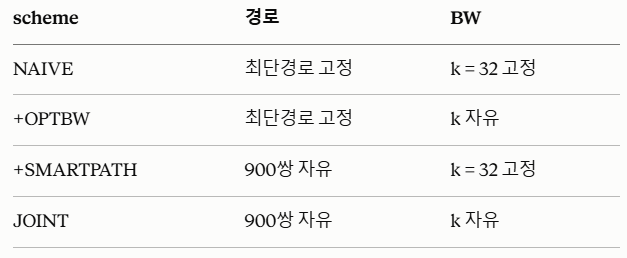

In [ ]:
# =========================================================
# Equal-BW 조건으로 planner 실행 → SMARTPATH
# =========================================================
SMART_PAIR_SUMMARIES, SMART_I, SMART_J, SMARTPATH_RESULT, SMARTPATH_MODE = (
    optimize_candidate_pairs(
        AMR1_CANDIDATE_PATHS,
        AMR2_CANDIDATE_PATHS,
        bw_mode="equal",
        verbose=False,
    )
)


# =========================================================
# Opt-BW 조건으로 planner 실행 → JOINT
# =========================================================
PAIR_SUMMARIES, JOINT_I, JOINT_J, JOINT_RESULT, JOINT_MODE = (
    optimize_candidate_pairs(
        AMR1_CANDIDATE_PATHS,
        AMR2_CANDIDATE_PATHS,
        bw_mode="opt",
    )
)


# SMARTPATH가 선택한 실제 경로
SMART_PATH1 = AMR1_CANDIDATE_PATHS[SMART_I]
SMART_PATH2 = AMR2_CANDIDATE_PATHS[SMART_J]
SMART_PATH1_XY = cells_to_xy(SMART_PATH1)
SMART_PATH2_XY = cells_to_xy(SMART_PATH2)


# JOINT가 선택한 실제 경로
JOINT_PATH1 = AMR1_CANDIDATE_PATHS[JOINT_I]
JOINT_PATH2 = AMR2_CANDIDATE_PATHS[JOINT_J]
JOINT_PATH1_XY = cells_to_xy(JOINT_PATH1)
JOINT_PATH2_XY = cells_to_xy(JOINT_PATH2)


# =========================================================
# BEST는 JOINT 결과를 의미
# =========================================================
BEST_I, BEST_J = JOINT_I, JOINT_J
BEST_RESULT = JOINT_RESULT

BEST_PATH1, BEST_PATH2 = JOINT_PATH1, JOINT_PATH2
BEST_PATH1_XY, BEST_PATH2_XY = JOINT_PATH1_XY, JOINT_PATH2_XY
SELECTION_MODE = JOINT_MODE


# 결과 배열 변환 및 QoS 만족 개수
PAIR_SUMMARIES = np.asarray(PAIR_SUMMARIES, dtype=float)
SMART_PAIR_SUMMARIES = np.asarray(SMART_PAIR_SUMMARIES, dtype=float)

N_FEASIBLE = int(PAIR_SUMMARIES[:, 4].sum())
SMART_N_FEASIBLE = int(SMART_PAIR_SUMMARIES[:, 4].sum())


# =========================================================
# 4-scheme 비교
# =========================================================
SCHEMES = [
    ("NAIVE",      "Shortest ", "Equal", SHORTEST_EQUAL_RESULT, 0,       0),
    ("+OPTBW",     "Shortest ", "Opt  ", SHORTEST_OPT_RESULT,   0,       0),
    ("+SMARTPATH", "CommAware", "Equal", SMARTPATH_RESULT,      SMART_I, SMART_J),
    ("JOINT",      "CommAware", "Opt  ", JOINT_RESULT,          JOINT_I, JOINT_J),
]

print(f"\n\nQoS 기준: {R_QOS_REQUIRED_BPS/1e6:.0f} Mbps")
print(f"  Equal-BW planner 만족 조합: {SMART_N_FEASIBLE}/{len(SMART_PAIR_SUMMARIES)}"
      f"   ({SMARTPATH_MODE})")
print(f"  Opt-BW   planner 만족 조합: {N_FEASIBLE}/{len(PAIR_SUMMARIES)}"
      f"   ({JOINT_MODE})")

print(f"\n{'scheme':<11} {'Path':<10} {'BW':<6} {'쌍':<9}"
      f"{'R_min':>8} {'mean':>8} {'T':>8}   QoS")
print("-" * 72)

for name, path_kind, bw, res, i, j in SCHEMES:
    print(f"{name:<11} {path_kind:<10} {bw:<6} #{i+1:<3}#{j+1:<5}"
          f"{res['r_min_bps']/1e6:8.2f} {res['mean_rate_bps']/1e6:8.2f} "
          f"{res['mission_time_s']:8.2f}   {res['qos_feasible']}")

## 14. 4가지 Scheme에 대한 경로 시각화

In [ ]:
import matplotlib.patheffects as pe

# turbo 배경 위에서 선이 묻히지 않도록 검은 테두리
STROKE = [pe.withStroke(linewidth=3, foreground="black")]

SCHEME_PATHS = [
    ("NAIVE / +OPTBW  (shortest)",          "#e8e8e8",
     AMR1_SHORTEST_XY, AMR2_SHORTEST_XY),
    (f"+SMARTPATH  #{SMART_I+1},#{SMART_J+1}", "darkorange",
     SMART_PATH1_XY,   SMART_PATH2_XY),
    (f"JOINT  #{JOINT_I+1},#{JOINT_J+1}",      "red",
     JOINT_PATH1_XY,   JOINT_PATH2_XY),
]

fig, ax = plt.subplots(figsize=(11, 5.5))

# Task 1에서 계산한 평균 SNR 지도
im = ax.imshow(snr_db, origin="lower", extent=[0, ROOM_X, 0, ROOM_Y],
               cmap="turbo", aspect="equal")
plt.colorbar(im, ax=ax, label="Average SNR [dB]")

# 장애물 및 안전 버퍼 셀
blocked_mask = np.ma.masked_where(~blocked, blocked.astype(float))
ax.imshow(blocked_mask, origin="lower", extent=[0, ROOM_X, 0, ROOM_Y],
          cmap="Greys", vmin=0, vmax=1, alpha=0.75, aspect="equal")

# scheme별 경로 (AMR1 실선 / AMR2 점선)
for label, color, p1, p2 in SCHEME_PATHS:
    ax.plot(p1[:, 0], p1[:, 1], "-",  color=color, lw=2, zorder=5,
            label=label, path_effects=STROKE)
    ax.plot(p2[:, 0], p2[:, 1], "--", color=color, lw=2, zorder=5,
            path_effects=STROKE)

# 시작점 사각형 / 도착점 삼각형
for xy, marker in [(AMR1_SHORTEST_XY[0],  "s"), (AMR1_SHORTEST_XY[-1], "^"),
                   (AMR2_SHORTEST_XY[0],  "s"), (AMR2_SHORTEST_XY[-1], "^")]:
    ax.scatter(*xy, s=150, c="white", edgecolors="black",
               linewidths=1.5, marker=marker, zorder=6)

ax.scatter(*BS_CENTER[:2], s=340, c="white", edgecolors="black",
           linewidths=1.5, marker="*", zorder=7, label="BS")

ax.set(xlim=(0, ROOM_X), ylim=(0, ROOM_Y), xlabel="x [m]", ylabel="y [m]")
ax.set_title(
    f"Paths by scheme  (solid: AMR1 / dashed: AMR2)   |   "
)
ax.grid(alpha=0.2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "05_paths_by_scheme.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# =========================================================
# scheme별 경로를 4개 패널에 나눠 그리기
# =========================================================
import matplotlib.patheffects as pe

STROKE = [pe.withStroke(linewidth=3, foreground="black")]

PANELS = [
    ("NAIVE",      SHORTEST_EQUAL_RESULT, AMR1_SHORTEST_XY, AMR2_SHORTEST_XY, 0,       0),
    ("+OPTBW",     SHORTEST_OPT_RESULT,   AMR1_SHORTEST_XY, AMR2_SHORTEST_XY, 0,       0),
    ("+SMARTPATH", SMARTPATH_RESULT,      SMART_PATH1_XY,   SMART_PATH2_XY,   SMART_I, SMART_J),
    ("JOINT",      JOINT_RESULT,          JOINT_PATH1_XY,   JOINT_PATH2_XY,   JOINT_I, JOINT_J),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, sharey=True)
blocked_mask = np.ma.masked_where(~blocked, blocked.astype(float))

for ax, (name, res, p1, p2, i, j) in zip(axes.ravel(), PANELS):
    im = ax.imshow(snr_db, origin="lower", extent=[0, ROOM_X, 0, ROOM_Y],
                   cmap="turbo", aspect="equal", vmin=snr_db.min(), vmax=snr_db.max())
    ax.imshow(blocked_mask, origin="lower", extent=[0, ROOM_X, 0, ROOM_Y],
              cmap="Greys", vmin=0, vmax=1, alpha=0.75, aspect="equal")

    # 경로 (AMR1 실선 / AMR2 점선)
    ax.plot(p1[:, 0], p1[:, 1], "-",  color="cyan",   lw=2, zorder=5,
            path_effects=STROKE, label=f"AMR1 #{i+1}")
    ax.plot(p2[:, 0], p2[:, 1], "--", color="orange", lw=2, zorder=5,
            path_effects=STROKE, label=f"AMR2 #{j+1}")

    # 시작점 사각형 / 도착점 삼각형
    for xy, marker in [(p1[0], "s"), (p1[-1], "^"), (p2[0], "s"), (p2[-1], "^")]:
        ax.scatter(*xy, s=110, c="white", edgecolors="black",
                   linewidths=1.3, marker=marker, zorder=6)

    ax.scatter(*BS_CENTER[:2], s=260, c="white", edgecolors="black",
               linewidths=1.3, marker="*", zorder=7)

    # R_min이 발생한 시점의 두 AMR 위치
    w = res["worst_idx"]
    for pos in (res["pos1_xy"][w], res["pos2_xy"][w]):
        ax.scatter(*pos, s=240, facecolors="none", edgecolors="white",
                   linewidths=3.5, zorder=8)
        ax.scatter(*pos, s=240, facecolors="none", edgecolors="red",
                   linewidths=1.5, zorder=9)

    k = res["split_k"]
    ax.set_title(f"{name}   T={res['mission_time_s']:.2f} s, "
                 f"R_min={res['r_min_bps']/1e6:.2f} Mbps, "
                 f"k*={k.min()}~{k.max()}", fontsize=11)
    ax.set(xlim=(0, ROOM_X), ylim=(0, ROOM_Y))
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)

for ax in axes[-1]:
    ax.set_xlabel("x [m]")
for ax in axes[:, 0]:
    ax.set_ylabel("y [m]")

fig.colorbar(im, ax=axes, label="Average SNR [dB]", fraction=0.02, pad=0.02)
fig.suptitle("Paths by scheme (solid: AMR1, dashed: AMR2, circle: worst-rate instant)",
             fontsize=13)
fig.savefig(FIGURES_DIR / "06_paths_per_scheme.png", dpi=150, bbox_inches="tight")
plt.show()

## 15. joint 경로를 애니메이션으로 저장하기

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

plt.rcParams["animation.embed_limit"] = 100.0
FRAME_STEP = 2

times = BEST_RESULT["time_s"]
pos1 = BEST_RESULT["pos1_xy"]
pos2 = BEST_RESULT["pos2_xy"]

frames = np.arange(0, len(times), FRAME_STEP, dtype=int)
if frames[-1] != len(times) - 1:
    frames = np.append(frames, len(times) - 1)

# 배경
fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)

im = ax.imshow(
    snr_db, origin="lower", extent=[0, ROOM_X, 0, ROOM_Y],
    cmap="turbo", aspect="equal"
)
plt.colorbar(
    im, ax=ax, label="Average SNR [dB]",
    fraction=0.03, pad=0.02, shrink=0.85
)

blocked_mask = np.ma.masked_where(~blocked, blocked.astype(float))
ax.imshow(
    blocked_mask, origin="lower", extent=[0, ROOM_X, 0, ROOM_Y],
    cmap="Greys", vmin=0, vmax=1, alpha=0.75, aspect="equal"
)

ax.scatter(
    BS_CENTER[0], BS_CENTER[1], s=170, c="red",
    edgecolors="white", marker="*", label="BS", zorder=7
)

# 검은 테두리가 있는 전체 예정 경로
def draw_planned_path(path_xy, color):
    dash = (0, (6, 3))
    ax.plot(
        path_xy[:, 0], path_xy[:, 1], linestyle=dash,
        color="black", linewidth=4.0, alpha=0.9, zorder=4
    )
    ax.plot(
        path_xy[:, 0], path_xy[:, 1], linestyle=dash,
        color=color, linewidth=2.2, alpha=1.0, zorder=4.1
    )

draw_planned_path(BEST_PATH1_XY, "cyan")
draw_planned_path(BEST_PATH2_XY, "orange")

# 실제로 지나온 경로와 현재 위치
amr1_trail, = ax.plot([], [], "-", color="cyan", linewidth=2.5, zorder=5)
amr2_trail, = ax.plot([], [], "-", color="orange", linewidth=2.5, zorder=5)

amr1_dot = ax.scatter(
    [], [], s=130, c="cyan", edgecolors="black",
    marker="o", label="AMR1", zorder=6
)
amr2_dot = ax.scatter(
    [], [], s=130, c="orange", edgecolors="black",
    marker="o", label="AMR2", zorder=6
)

status_text = ax.text(
    0.02, 0.96, "", transform=ax.transAxes,
    ha="left", va="top", fontsize=9,
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "black"},
    zorder=8
)

ax.set(
    xlim=(0, ROOM_X), ylim=(0, ROOM_Y),
    xlabel="x [m]", ylabel="y [m]"
)
ax.set_title("Selected AMR Path Animation", pad=4)
ax.grid(alpha=0.2)
ax.legend(loc="upper right", fontsize=9)

# 프레임 갱신
def update(frame_idx):
    amr1_dot.set_offsets(pos1[frame_idx][None, :])
    amr2_dot.set_offsets(pos2[frame_idx][None, :])

    amr1_trail.set_data(pos1[:frame_idx + 1, 0], pos1[:frame_idx + 1, 1])
    amr2_trail.set_data(pos2[:frame_idx + 1, 0], pos2[:frame_idx + 1, 1])

    current_time = times[frame_idx]
    rate1_mbps = BEST_RESULT["rate1_bps"][frame_idx] / 1e6
    rate2_mbps = BEST_RESULT["rate2_bps"][frame_idx] / 1e6
    split_k = BEST_RESULT["split_k"][frame_idx]

    status_text.set_text(
        f"t={current_time:.1f} s  |  "
        f"AMR1={rate1_mbps:.1f} Mbps  |  "
        f"AMR2={rate2_mbps:.1f} Mbps  |  "
        f"BW={split_k}:{N_SC-split_k}"
    )

    return amr1_dot, amr2_dot, amr1_trail, amr2_trail, status_text

animation = FuncAnimation(
    fig, update, frames=frames,
    interval=SIM_DT * FRAME_STEP * 1000,
    blit=True, repeat=False
)

plt.close(fig)
HTML(animation.to_jshtml(default_mode="once"))

## 16. 최종 결과 저장

In [ ]:

SCHEME_RESULTS = {
    "naive": SHORTEST_EQUAL_RESULT,
    "optbw": SHORTEST_OPT_RESULT,
    "smartpath": SMARTPATH_RESULT,
    "joint": JOINT_RESULT,
}

SAVE_KEYS = (
    "time_s", "pos1_xy", "pos2_xy",
    "snr1_sc", "snr2_sc", "split_k",
    "rate1_bps", "rate2_bps", "min_rate_bps",
    "r_min_bps", "mean_rate_bps", "mission_time_s",
)

save_data = {}

for scheme, result in SCHEME_RESULTS.items():
    for key in SAVE_KEYS:
        save_data[f"{scheme}_{key}"] = result[key]

save_data.update({
    # QoS와 900개 경로쌍 평가 결과
    "r_qos_required_bps": R_QOS_REQUIRED_BPS,
    "pair_summaries": PAIR_SUMMARIES[:, :4],

    # 30개 후보 경로의 길이
    "amr1_candidate_lengths": np.asarray(
        AMR1_CANDIDATE_LENGTHS,
        dtype=float,
    ),
    "amr2_candidate_lengths": np.asarray(
        AMR2_CANDIDATE_LENGTHS,
        dtype=float,
    ),

    # 최단경로 좌표와 길이
    "shortest_path1_xy": AMR1_SHORTEST_XY,
    "shortest_path2_xy": AMR2_SHORTEST_XY,
    "shortest_path1_length_m": AMR1_SHORTEST_LENGTH_M,
    "shortest_path2_length_m": AMR2_SHORTEST_LENGTH_M,

    # SMARTPATH 선택 경로 좌표와 길이
    "smartpath_path1_xy": SMART_PATH1_XY,
    "smartpath_path2_xy": SMART_PATH2_XY,
    "smartpath_path1_length_m": AMR1_CANDIDATE_LENGTHS[SMART_I],
    "smartpath_path2_length_m": AMR2_CANDIDATE_LENGTHS[SMART_J],

    # JOINT 선택 경로 좌표와 길이
    "joint_path1_xy": JOINT_PATH1_XY,
    "joint_path2_xy": JOINT_PATH2_XY,
    "joint_path1_length_m": AMR1_CANDIDATE_LENGTHS[JOINT_I],
    "joint_path2_length_m": AMR2_CANDIDATE_LENGTHS[JOINT_J],
})

np.savez_compressed(PATH_PLANNING_RESULTS_PATH, **save_data)

print("Path-planning results saved:", PATH_PLANNING_RESULTS_PATH)
print("저장된 항목 수:", len(save_data))
print("저장된 경로쌍 결과:", save_data["pair_summaries"].shape)
print(
    "AMR1 후보 길이:",
    save_data["amr1_candidate_lengths"].shape,
)
print(
    "AMR2 후보 길이:",
    save_data["amr2_candidate_lengths"].shape,
)